In [1]:
import pandas as pd
import numpy as np

In [2]:
pd.set_option('display.max_rows',None)
pd.set_option('display.max_columns',None)

In [55]:
data=pd.read_csv('repair_cost.csv')

In [4]:
data.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [ ]:
data.describe()

In [5]:
data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [6]:
data=pd.get_dummies(data,columns=['Type'],drop_first=True)


In [7]:
data=data.apply(lambda x: x.astype(int) if x.dtype =='bool' else x)

In [ ]:
# data['Type'].value_counts()

In [7]:
data.columns


Index(['UDI', 'Product ID', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Type_L',
       'Type_M'],
      dtype='object')

In [ ]:
data.info()

## 📊 Analysis start:

### quan,qual:

In [8]:
data.drop('UDI',axis=1,inplace=True)

In [9]:
quan=[]
qual=[]
for column in data.columns:
    if data[column].dtype=='object':
        qual.append(column)
    else:
        quan.append(column)

In [ ]:
quan
# proces the quantitative columns

## check outlier in this dataset:

In [ ]:
data.head(10)

In [10]:
outlier_check_cols=['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]',]

In [65]:
# using min and max to separate lessor and greator outlier column is a easy method ,try next time:

lesser_column=[]
greater_column=[]
for col in outlier_check_cols:
    mins=np.percentile(data[col],0)
    maxs=np.percentile(data[col],100)
    # val=data[col].values
    q1=np.percentile(data[col],25)
    q3=np.percentile(data[col],75)
    IQR=q3-q1
    leser_range=q1-(1.5*(IQR))
    greater_range=q3+(1.5*(IQR))
    # print(f'column : {col}\nlesser_range :{lesor_range}\ngreater_range :{greater_range}\n\n')
    
    if mins<leser_range:
        lesser_column.append(col)
    if maxs>greater_range:
        greater_column.append(col)   

In [66]:
lesser_column

[]

In [67]:
greater_column
# clean outliers...

[]

## replace outliers:

In [63]:
for i in lesser_column:
    data[i]=np.where(data[i]<leser_range,leser_range,data[i])


In [64]:
for j in greater_column:
    data[j]=np.where(data[j]>greater_range,greater_range,data[j])

## frequency :

In [39]:
# for co in quan:
#     print(co)
#     print(data[co].kurt())
#     print()

In [32]:
data.head()

,Product ID,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
0,M14860,298.1,308.6,67.2,42.8,0,0,0,0,0,0,0,0,1
1,L47181,298.2,308.7,67.2,46.3,3,0,0,0,0,0,0,1,0
2,L47182,298.1,308.5,67.2,49.4,5,0,0,0,0,0,0,1,0
3,L47183,298.2,308.6,67.2,39.5,7,0,0,0,0,0,0,1,0
4,L47184,298.2,308.7,67.2,40.0,9,0,0,0,0,0,0,1,0


In [38]:
data.drop('Product ID',axis=1,inplace=True)

In [20]:
data.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
0,298.1,308.6,67.2,42.8,0,0,0,0,0,0,0,0,1
1,298.2,308.7,67.2,46.3,3,0,0,0,0,0,0,1,0
2,298.1,308.5,67.2,49.4,5,0,0,0,0,0,0,1,0
3,298.2,308.6,67.2,39.5,7,0,0,0,0,0,0,1,0
4,298.2,308.7,67.2,40.0,9,0,0,0,0,0,0,1,0


## distribution:

In [21]:
import seaborn as sns

In [22]:
import matplotlib.pyplot as plt

C:\Users\Smile\AppData\Local\Temp\ipykernel_13472\1616703012.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Machine failure'],kde=True,hist=True,color='red')


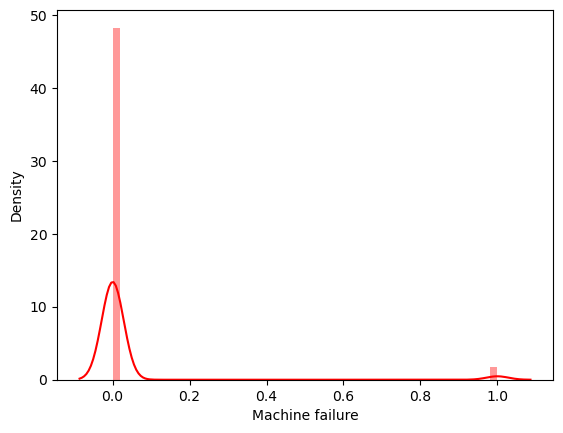

In [23]:
sns.distplot(data['Machine failure'],kde=True,hist=True,color='red')
plt.show()

In [24]:
data['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

C:\Users\Smile\AppData\Local\Temp\ipykernel_13472\292255400.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Air temperature [K]'],kde=True)


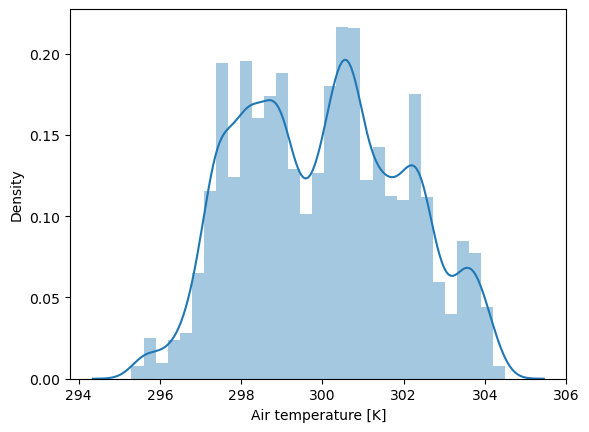

In [32]:
sns.distplot(data['Air temperature [K]'],kde=True)
plt.show()

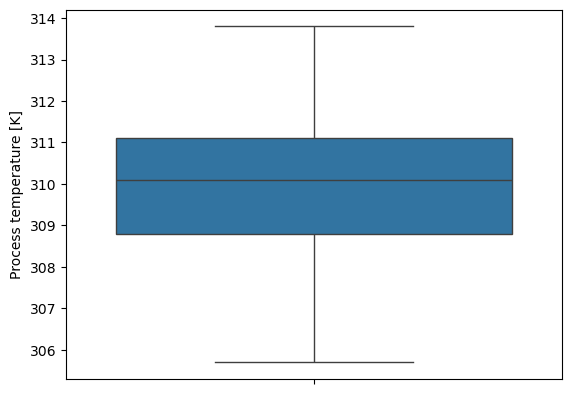

In [36]:
sns.boxplot(data['Process temperature [K]'])
plt.show()

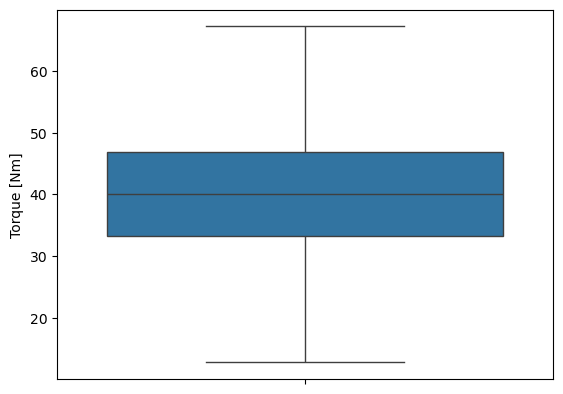

In [51]:
sns.boxplot(data['Torque [Nm]'])
plt.show()

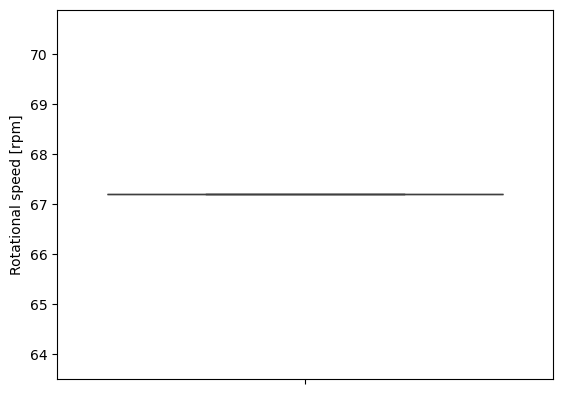

In [52]:
sns.boxplot(data['Rotational speed [rpm]'])
plt.show()

In [54]:
data['Rotational speed [rpm]'].value_counts()
# no outliers now...

Rotational speed [rpm]
67.2    10000
Name: count, dtype: int64

In [68]:
## save dataset :
data.to_csv('clean_repair_cost_predict.csv',index=False)